# ⚡ Reworked Power Grid Demand Surge Benchmark (Hourly, Weather-Onset Aligned)

### Data Sources
- **Hourly Electricity Demand, Forecast, Interchange & Fuel Mix:** [U.S. EIA-930 Electric Grid Monitor (`EIA930_BALANCE`)](https://www.eia.gov/electricity/gridmonitor/)
- **Hourly Regional Weather & Solar Irradiance (`past_future` forcing):** [NASA POWER (`MERRA-2` Reanalysis)](https://power.larc.nasa.gov/)
- **Balancing Authority Coordinates & Installed Capacity Metadata:** [Electricity Maps Zones (`EIA.gov` capacities)](https://github.com/electricitymaps/electricitymaps-contrib)

### Benchmark Design Highlights
1. **Exogenous Onset ($	au = 0$):** Defined strictly from NASA POWER hourly temperature threshold crossings into regional extreme **heatwaves** or **Arctic freezes** (never from peak MW demand).
2. **Normal Baseline Before $	au = 0$, Sustained Surge After:** `[-72h, -1h]` normal diurnal baseline followed by a multi-day `+15%..+55%` AC/heating load surge over `[0h, +72h]`.
3. **True `past_future` Forcing:** Weather (`temp_c`, `thermal_discomfort_c`, `humidity_pct`, `solar_wm2`, `wind_ms`, `pressure_hpa`) and local schedules (`local_hour`, `day_of_week`) directly govern electric cooling, heating, and behind-the-meter solar offset.
4. **Chronological Split (`2021–2023` Train vs. `2024` Test):** Strict non-overlapping split (`N = 573` or `569` verified zero-NaN events across 50 US Balancing Authorities).

### 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

### 2. Load Full Dataset, Summary & Feature Inventory

In [2]:
npz_path = 'data/reworked_power_grid_hourly.npz'
meta_path = 'data/reworked_power_grid_metadata.csv'

data = np.load(npz_path, allow_pickle=True)
meta = pd.read_csv(meta_path)

past_names = [str(x) for x in data['past_feature_names']]
pf_names = [str(x) for x in data['past_future_feature_names']]
static_names = [str(x) for x in data['static_feature_names']]
tau_steps = data['tau_steps']
ts_grid = data['timestamps_utc']

print(f'Samples (N):           {len(meta)}')
print(f'Hours per sample (T):  {len(tau_steps)} (tau from {tau_steps[0]} to {tau_steps[-1]} hours)')
print(f'Past covariates:       {len(past_names)} -> {past_names}')
print(f'Past-future covs:      {len(pf_names)} -> {pf_names}')
print(f'Static features:       {len(static_names)} -> {static_names}')

X_past = data['past_covariates']
X_pf = data['past_future_covariates']
X_static = data['static_features']
N, T, _ = X_past.shape

full_dict = {
    'sample_id': np.repeat(meta['sample_id'].values, T),
    'ba': np.repeat(meta['ba'].values, T),
    'region': np.repeat(meta['region'].values, T),
    'split': np.repeat(meta['split'].values, T),
    'event_type': np.repeat(meta['event_type'].values, T),
    'onset_utc': np.repeat(meta['onset_utc'].values, T),
    'timestamp_utc': ts_grid.reshape(-1),
    'tau_hour': np.tile(tau_steps, N),
}
for i, col in enumerate(static_names):
    full_dict[col] = np.repeat(X_static[:, i], T)
for i, col in enumerate(past_names):
    full_dict[col] = X_past[:, :, i].reshape(-1)
for i, col in enumerate(pf_names):
    full_dict[col] = X_pf[:, :, i].reshape(-1)

full_df = pd.DataFrame(full_dict)
print(f'\nFlattened full table shape: {full_df.shape}')
display(meta.head())
display(full_df[past_names + pf_names].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Samples (N):           569
Hours per sample (T):  145 (tau from -72 to 72 hours)
Past covariates:       11 -> ['load_mw', 'demand_forecast_mw', 'net_gen_mw', 'load_rolling_mean_24h', 'load_change_1h', 'gas_gen_mw', 'coal_gen_mw', 'gas_share', 'solar_share', 'wind_share', 'import_share']
Past-future covs:      8 -> ['temp_c', 'apparent_temp_c', 'humidity_pct', 'solar_wm2', 'wind_ms', 'pressure_hpa', 'local_hour', 'day_of_week']
Static features:       3 -> ['latitude', 'longitude', 'installed_cap_mw']

Flattened full table shape: (82505, 30)


,sample_id,ba,region,split,event_type,onset_utc,window_start_utc,window_end_utc,baseline_mean_mw,pre_peak_mw,post_peak_mw,post_peak_tau_hour,peak_surge_ratio,latitude,longitude,installed_cap_mw
0,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 09:00:00,2021-01-08 09:00:00,6259.2,8232.0,10745.0,52,1.305,35.1975,-78.1226,17488.1
1,1,DUK,CAR,train,freeze,2021-01-06 03:00:00,2021-01-03 03:00:00,2021-01-09 03:00:00,11593.0,14366.0,16955.0,34,1.180,35.3181,-81.2942,30185.7
2,2,SCEG,CAR,train,freeze,2021-01-06 09:00:00,2021-01-03 09:00:00,2021-01-09 09:00:00,2582.8,3045.0,3671.0,28,1.206,33.4102,-81.0116,8121.9
3,3,ERCO,TEX,train,freeze,2021-01-08 07:00:00,2021-01-05 07:00:00,2021-01-11 07:00:00,39891.3,45753.0,55254.0,66,1.208,30.9631,-99.4031,175697.2
4,4,PACW,NW,train,freeze,2021-01-18 09:00:00,2021-01-15 09:00:00,2021-01-21 09:00:00,2448.1,2939.0,3421.0,55,1.164,43.1244,-121.0422,2623.4


,count,mean,std,min,50%,max
load_mw,82505.0,10520.09,19172.39,141.00,3106.00,142680.00
demand_forecast_mw,82505.0,10432.87,19087.26,-71.00,2980.00,146170.00
net_gen_mw,82505.0,10309.43,19652.36,64.00,2560.00,147639.00
load_rolling_mean_24h,82505.0,10381.65,18730.92,180.58,3006.75,127331.84
load_change_1h,82505.0,16.99,776.84,-30611.00,1.00,30511.00
gas_gen_mw,82505.0,3731.24,8119.94,-4.00,841.00,69905.00
coal_gen_mw,82505.0,2191.20,4762.11,-50.00,448.00,41411.00
gas_share,82505.0,0.38,0.27,0.00,0.34,1.00
solar_share,82505.0,0.04,0.09,0.00,0.00,0.72
wind_share,82505.0,0.05,0.11,0.00,0.00,0.81


### 3. Derived Feature Evaluation & Correlation Matrix (Justifying Redundancy Removal)

Highly correlated feature pairs (|r| > 0.90):
  - load_mw                  vs demand_forecast_mw      : r = +0.998
  - load_mw                  vs net_gen_mw              : r = +0.996
  - load_mw                  vs load_rolling_mean_24h   : r = +0.990
  - load_mw                  vs gas_gen_mw              : r = +0.956
  - load_mw                  vs coal_gen_mw             : r = +0.905
  - demand_forecast_mw       vs net_gen_mw              : r = +0.995
  - demand_forecast_mw       vs load_rolling_mean_24h   : r = +0.988
  - demand_forecast_mw       vs gas_gen_mw              : r = +0.954
  - demand_forecast_mw       vs coal_gen_mw             : r = +0.907
  - net_gen_mw               vs load_rolling_mean_24h   : r = +0.987
  - net_gen_mw               vs gas_gen_mw              : r = +0.956
  - net_gen_mw               vs coal_gen_mw             : r = +0.906
  - load_rolling_mean_24h    vs gas_gen_mw              : r = +0.938
  - temp_c                   vs apparent_temp_c         :

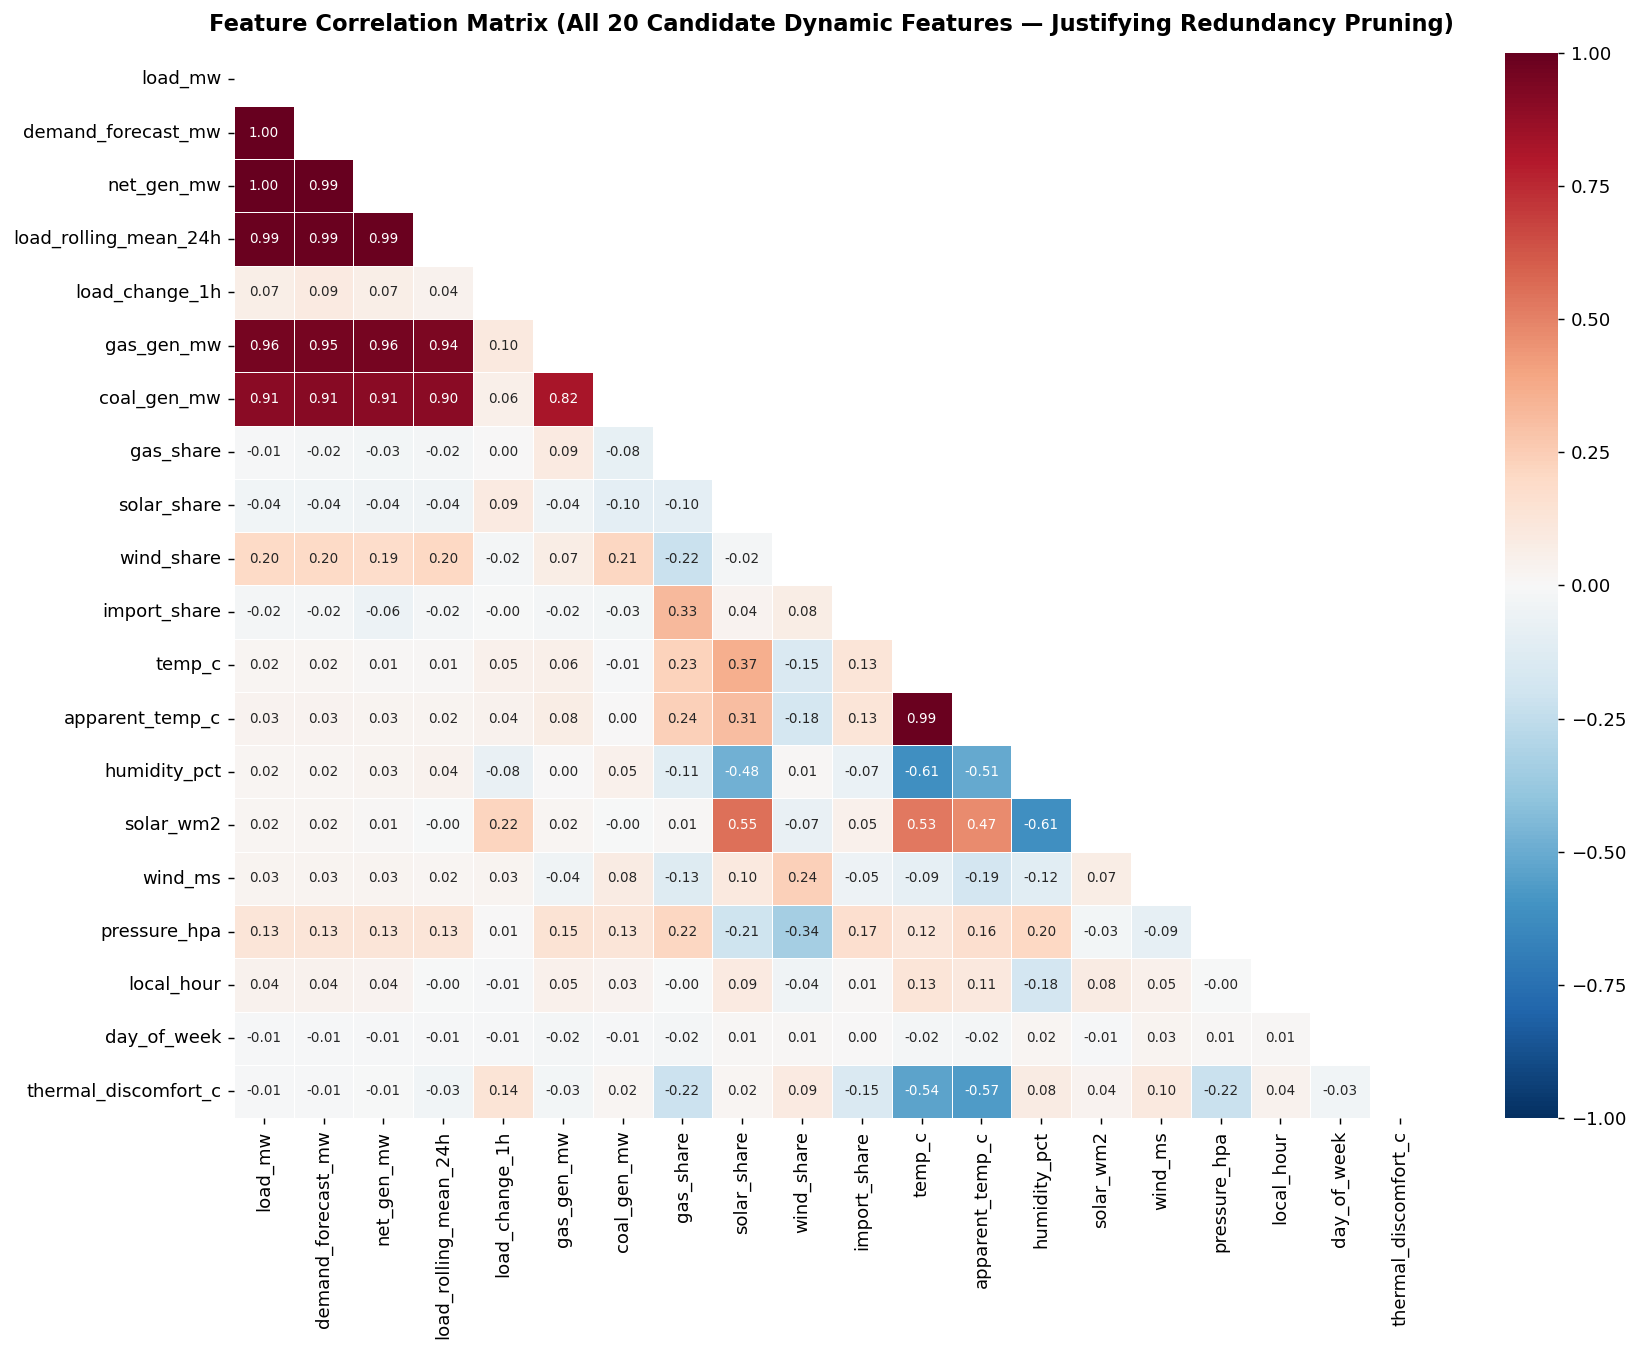

In [3]:
# Engineer V-shaped thermal discomfort index: |temp_c - 18.0| C
# Captures both extreme summer cooling (AC) and winter heating loads in a single non-redundant metric
full_df['thermal_discomfort_c'] = np.abs(full_df['temp_c'] - 18.0)

all_candidate_features = past_names + pf_names + ['thermal_discomfort_c']
corr = full_df[all_candidate_features].corr()

print('Highly correlated feature pairs (|r| > 0.90):')
for i in range(len(all_candidate_features)):
    for j in range(i + 1, len(all_candidate_features)):
        val = corr.iloc[i, j]
        if abs(val) > 0.90:
            print(f'  - {all_candidate_features[i]:24s} vs {all_candidate_features[j]:24s}: r = {val:+.3f}')

print('\nDerived feature correlations with primary target (load_mw):')
for dcol in ['load_change_1h', 'gas_share', 'import_share', 'thermal_discomfort_c']:
    print(f'  - {dcol:24s} vs load_mw: r = {corr.loc[dcol, "load_mw"]:+.3f}')

fig, ax = plt.subplots(figsize=(13.5, 10.5), dpi=130)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 7.5},
    ax=ax,
)
ax.set_title(
    'Feature Correlation Matrix (All 20 Candidate Dynamic Features — Justifying Redundancy Pruning)',
    fontsize=12.5,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.savefig('data/power_grid_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Create Clean Non-Redundant Simple Dataset (`data/power_grid_simple.csv`)

In [4]:
# Drop the 6 redundant scale/temperature duplicates where |r| > 0.90:
#   - demand_forecast_mw (r=+0.998 vs load_mw), net_gen_mw (r=+0.996 vs load_mw)
#   - load_rolling_mean_24h (r=+0.990 vs load_mw)
#   - gas_gen_mw (r=+0.956 vs load_mw) & coal_gen_mw (r=+0.905 vs load_mw) -> scale-invariant gas_share kept instead
#   - apparent_temp_c (r=+0.988 vs temp_c) -> keep temp_c + thermal_discomfort_c
REDUNDANT_TO_DROP = [
    'demand_forecast_mw',
    'net_gen_mw',
    'load_rolling_mean_24h',
    'gas_gen_mw',
    'coal_gen_mw',
    'apparent_temp_c',
]

KEEP_META = ['sample_id', 'ba', 'region', 'split', 'event_type', 'onset_utc', 'timestamp_utc', 'tau_hour']
KEEP_STATIC = static_names
KEEP_PAST = [c for c in past_names if c not in REDUNDANT_TO_DROP]
KEEP_PF = [c for c in pf_names + ['thermal_discomfort_c'] if c not in REDUNDANT_TO_DROP]

simple_df = full_df[KEEP_META + KEEP_STATIC + KEEP_PAST + KEEP_PF].copy()
simple_df['local_hour'] = simple_df['local_hour'].astype(int)
simple_df['day_of_week'] = simple_df['day_of_week'].astype(int)

kept_dyn = KEEP_PAST + KEEP_PF
kept_corr = simple_df[kept_dyn].corr().copy()
np.fill_diagonal(kept_corr.values, 0.0)
max_r = float(kept_corr.abs().max().max())

X_std = (simple_df[kept_dyn] - simple_df[kept_dyn].mean()) / simple_df[kept_dyn].std()
vifs = dict(zip(kept_dyn, np.diag(np.linalg.inv(np.corrcoef(X_std.values, rowvar=False)))))

print(f'Dropped {len(REDUNDANT_TO_DROP)} redundant features: {REDUNDANT_TO_DROP}')
print(f'Max off-diagonal |r| among {len(kept_dyn)} kept dynamic features: {max_r:.3f}')
print(f'Max VIF across kept dynamic features: {max(vifs.values()):.2f} ({max(vifs, key=vifs.get)})')
assert simple_df.isna().sum().sum() == 0, 'Unexpected NaNs found!'

simple_csv_path = 'data/power_grid_simple.csv'
simple_df.to_csv(simple_csv_path, index=False)
print(f'Saved: {simple_csv_path} ({os.path.getsize(simple_csv_path) / (1024**2):.2f} MB), shape={simple_df.shape}')
display(simple_df.head())

Dropped 6 redundant features: ['demand_forecast_mw', 'net_gen_mw', 'load_rolling_mean_24h', 'gas_gen_mw', 'coal_gen_mw', 'apparent_temp_c']
Max off-diagonal |r| among 14 kept dynamic features: 0.612
Max VIF across kept dynamic features: 3.35 (temp_c)


Saved: data/power_grid_simple.csv (14.59 MB), shape=(82505, 25)


,sample_id,ba,region,split,event_type,onset_utc,timestamp_utc,tau_hour,latitude,longitude,installed_cap_mw,load_mw,load_change_1h,gas_share,solar_share,wind_share,import_share,temp_c,humidity_pct,solar_wm2,wind_ms,pressure_hpa,local_hour,day_of_week,thermal_discomfort_c
0,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 09:00:00,-72,35.197506,-78.122581,17488.099609,5258.0,-53.0,0.112456,0.000000,0.0,0.025865,17.799999,97.309998,0.00,5.64,1010.900024,4,5,0.200001
1,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 10:00:00,-71,35.197506,-78.122581,17488.099609,5295.0,37.0,0.118061,0.000000,0.0,0.033805,17.420000,97.449997,0.00,5.68,1011.200012,5,5,0.580000
2,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 11:00:00,-70,35.197506,-78.122581,17488.099609,5398.0,103.0,0.144386,0.000000,0.0,0.013338,16.990000,97.680000,0.00,5.27,1011.400024,6,5,1.010000
3,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 12:00:00,-69,35.197506,-78.122581,17488.099609,5602.0,204.0,0.174858,0.000000,0.0,-0.002499,16.580000,97.839996,6.25,4.57,1011.900024,7,5,1.420000
4,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 13:00:00,-68,35.197506,-78.122581,17488.099609,5785.0,183.0,0.208096,0.003346,0.0,-0.033362,17.100000,97.199997,79.93,4.95,1012.599976,8,5,0.900000


### 5. Feature Inventory: Past-Only vs. Past-Future vs. Static

In [5]:
DESC = {
    'sample_id': 'Integer event window ID',
    'ba': 'EIA-930 US Balancing Authority acronym',
    'region': 'EIA regional interconnection code (CAL, TEX, PJM/MIDA, etc.)',
    'split': 'Chronological split (train: 2021-2023 / test: 2024)',
    'event_type': 'Weather trigger type (heatwave / freeze)',
    'onset_utc': 'Exogenous extreme-temperature onset UTC timestamp (tau=0)',
    'timestamp_utc': 'Hourly UTC timestamp',
    'tau_hour': 'Hours relative to thermal onset (-72 to +72)',
    'latitude': 'BA centroid latitude (deg N)',
    'longitude': 'BA centroid longitude (deg E)',
    'installed_cap_mw': 'Total BA nameplate generation capacity (MW)',
    'load_mw': '[TARGET] Hourly system electricity demand (MW, EIA-930)',
    'load_change_1h': 'Hourly grid load ramp (load[t] - load[t-1], MW/hr)',
    'gas_share': 'Natural gas fraction of net generation (0-1)',
    'solar_share': 'Solar PV fraction of net generation (0-1)',
    'wind_share': 'Wind fraction of net generation (0-1)',
    'import_share': 'Net electricity import ratio (-interchange / load)',
    'temp_c': '2m air temperature (deg C, NASA POWER MERRA-2)',
    'thermal_discomfort_c': 'Absolute thermal departure |temp_c - 18.0| C (AC/heating proxy)',
    'humidity_pct': '2m relative humidity (%, MERRA-2)',
    'solar_wm2': 'Downward shortwave solar irradiance (W/m^2, MERRA-2)',
    'wind_ms': '10m wind speed (m/s, MERRA-2)',
    'pressure_hpa': 'Surface barometric pressure (hPa, MERRA-2)',
    'local_hour': 'Local hour of day (0-23, diurnal load cycle)',
    'day_of_week': 'Local day of week (0=Mon .. 6=Sun)',
}

rows = []
for c in KEEP_META:
    rows.append({'column': c, 'role': 'METADATA', 'description': DESC[c]})
for c in KEEP_STATIC:
    rows.append({'column': c, 'role': 'STATIC', 'description': DESC[c]})
for c in KEEP_PAST:
    role = 'PAST_ONLY (TARGET)' if c == 'load_mw' else 'PAST_ONLY'
    rows.append({'column': c, 'role': role, 'description': DESC[c]})
for c in KEEP_PF:
    rows.append({'column': c, 'role': 'PAST_FUTURE', 'description': DESC[c]})

display(pd.DataFrame(rows))

,column,role,description
0,sample_id,METADATA,Integer event window ID
1,ba,METADATA,EIA-930 US Balancing Authority acronym
2,region,METADATA,"EIA regional interconnection code (CAL, TEX, P..."
3,split,METADATA,Chronological split (train: 2021-2023 / test: ...
4,event_type,METADATA,Weather trigger type (heatwave / freeze)
5,onset_utc,METADATA,Exogenous extreme-temperature onset UTC timest...
6,timestamp_utc,METADATA,Hourly UTC timestamp
7,tau_hour,METADATA,Hours relative to thermal onset (-72 to +72)
8,latitude,STATIC,BA centroid latitude (deg N)
9,longitude,STATIC,BA centroid longitude (deg E)


### 6. Chronological Train / Test Split Summary

In [6]:
split_summary = meta.groupby('split').agg(
    num_events=('sample_id', 'count'),
    num_bas=('ba', 'nunique'),
    heatwaves=('event_type', lambda s: int((s == 'heatwave').sum())),
    freezes=('event_type', lambda s: int((s == 'freeze').sum())),
    earliest_window=('window_start_utc', 'min'),
    latest_window=('window_end_utc', 'max'),
    median_pre_peak_mw=('pre_peak_mw', 'median'),
    median_post_peak_mw=('post_peak_mw', 'median'),
    median_peak_ratio=('peak_surge_ratio', 'median'),
)
display(split_summary)

train_end = meta.loc[meta['split'] == 'train', 'window_end_utc'].max()
test_start = meta.loc[meta['split'] == 'test', 'window_start_utc'].min()
print(f'Chronological separation verified: latest train window end ({train_end}) < earliest test window start ({test_start})')

,num_events,num_bas,heatwaves,freezes,earliest_window,latest_window,median_pre_peak_mw,median_post_peak_mw,median_peak_ratio
split,,,,,,,,,
test,130,43,73,57,2024-01-07 09:00:00,2024-12-24 12:00:00,3517.5,4342.5,1.2105
train,439,48,214,225,2021-01-02 09:00:00,2024-01-02 06:00:00,3495.0,4270.0,1.2080


Chronological separation verified: latest train window end (2024-01-02 06:00:00) < earliest test window start (2024-01-07 09:00:00)


### 7. Before & After Surge Visualization (1 Sample Grid + All Train vs. Test Events)

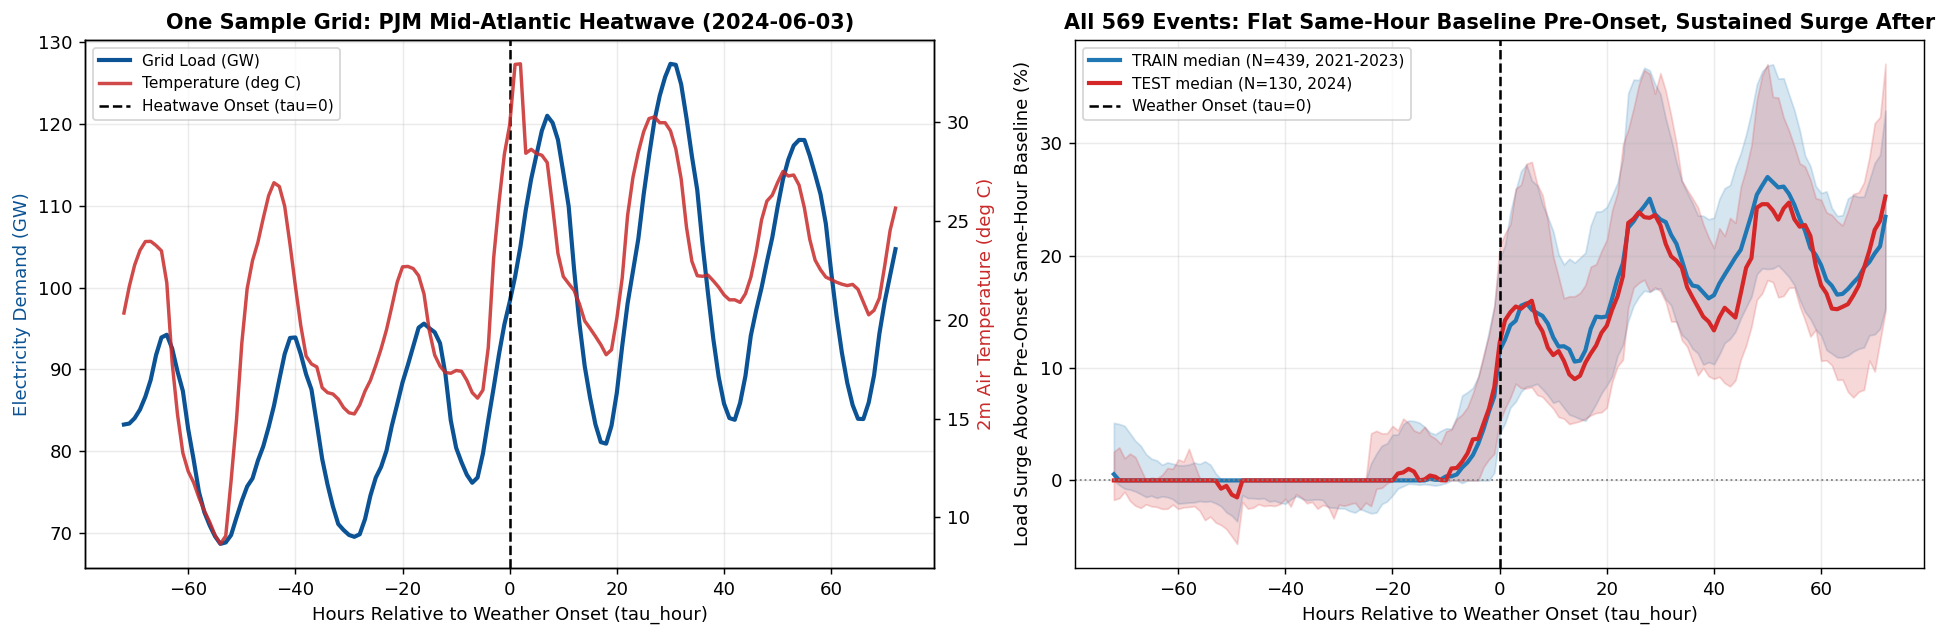

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130)

# --- Left Panel: One Sample Event (PJM June 2024 Heatwave, Test Split) ---
pjm_ex = simple_df[simple_df['sample_id'] == meta[(meta['ba'] == 'PJM') & (meta['split'] == 'test') & (meta['event_type'] == 'heatwave')]['sample_id'].iloc[0]].sort_values('tau_hour')
ax1 = axes[0]
ax1_r = ax1.twinx()

l1, = ax1.plot(pjm_ex['tau_hour'], pjm_ex['load_mw'] / 1000.0, color='#0b5394', lw=2.3, label='Grid Load (GW)')
l2, = ax1_r.plot(pjm_ex['tau_hour'], pjm_ex['temp_c'], color='#c92a2a', lw=1.9, alpha=0.85, label='Temperature (deg C)')
v1 = ax1.axvline(0, color='black', ls='--', lw=1.4, label='Heatwave Onset (tau=0)')

ax1.set_title(f'One Sample Grid: PJM Mid-Atlantic Heatwave ({pjm_ex["onset_utc"].iloc[0][:10]})', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Hours Relative to Weather Onset (tau_hour)')
ax1.set_ylabel('Electricity Demand (GW)', color='#0b5394')
ax1_r.set_ylabel('2m Air Temperature (deg C)', color='#c92a2a')
ax1.grid(True, alpha=0.25)
ax1.legend([l1, l2, v1], [l1.get_label(), l2.get_label(), v1.get_label()], loc='upper left', fontsize=8.5)

# --- Right Panel: All Events — Load % Above Same-Hour Pre-Onset Diurnal Baseline ---
pre_hr_med = (
    simple_df[simple_df['tau_hour'] < 0]
    .groupby(['sample_id', 'local_hour'])['load_mw']
    .median()
    .rename('pre_same_hr_mw')
    .reset_index()
)
df_rel = simple_df.merge(pre_hr_med, on=['sample_id', 'local_hour'], how='left')
df_rel['excess_load_pct'] = (df_rel['load_mw'] / df_rel['pre_same_hr_mw'] - 1.0) * 100.0

ax2 = axes[1]
n_tr = meta[meta['split'] == 'train'].shape[0]
n_te = meta[meta['split'] == 'test'].shape[0]
for split_name, color, label in [('train', '#1f77b4', f'TRAIN median (N={n_tr}, 2021-2023)'),
                                 ('test', '#d62728', f'TEST median (N={n_te}, 2024)')]:
    sub = df_rel[df_rel['split'] == split_name]
    stats = sub.groupby('tau_hour')['excess_load_pct'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax2.plot(stats['tau_hour'], stats['med'], color=color, lw=2.3, label=label)
    ax2.fill_between(stats['tau_hour'], stats['q25'], stats['q75'], color=color, alpha=0.18)

ax2.axhline(0, color='gray', ls=':', lw=1.0)
ax2.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax2.set_title(f'All {len(meta)} Events: Flat Same-Hour Baseline Pre-Onset, Sustained Surge After', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Hours Relative to Weather Onset (tau_hour)')
ax2.set_ylabel('Load Surge Above Pre-Onset Same-Hour Baseline (%)')
ax2.grid(True, alpha=0.25)
ax2.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig('data/power_grid_simple_overview.png', dpi=150, bbox_inches='tight')
plt.show()